# Customer Churn: Exploratory Data Analysis

**Business problem:** Losing customers is expensive. If we can understand *who* is likely to leave and *why*, the business can act before they go.

**Objective of this notebook:**
- Inspect dataset structure, data types, and descriptive statistics.
- Audit data quality (missing values & informativeness, duplicate analysis & train/test leakage prevention, categorical consistency, and continuous outliers).
- Address temporal and target data leakage risks before moving to pipeline design.
- Analyze target distribution (`Churn`), univariate features, and bivariate relationships with `Churn`.
- Formulate concrete **Key Insights & Recommendations** backed by exact figures, data quality decisions, and an actionable feature engineering plan.

## 1. Import & settings

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 100

DATA_PATH = "../data/raw/customer_churn.csv"

## 2. Load the data

In [19]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 3,941 | Columns: 11


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.00,29.00,4,Laptop & Accessory,3,Single,2,0,7.00,143.32,0
1,7.00,25.00,4,Mobile,1,Married,2,0,7.00,129.29,0
2,27.00,13.00,3,Laptop & Accessory,1,Married,5,0,7.00,168.54,0
3,20.00,25.00,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.00,15.00,4,Others,4,Single,8,0,8.00,322.17,0


### 2.1 Target definition & schema inspection

In [20]:
TARGET = "Churn"

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   object 
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   object 
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 338.8+ KB


### 2.2 Descriptive statistics

In [22]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Tenure,"3,747.00",10.08,8.50,0.00,2.00,9.00,16.00,61.00
WarehouseToHome,"3,772.00",15.65,8.45,5.00,9.00,14.00,21.00,127.00
NumberOfDeviceRegistered,"3,941.00",3.68,1.01,1.00,3.00,4.00,4.00,6.00
SatisfactionScore,"3,941.00",3.09,1.38,1.00,2.00,3.00,4.00,5.00
NumberOfAddress,"3,941.00",4.24,2.63,1.00,2.00,3.00,6.00,22.00
Complain,"3,941.00",0.28,0.45,0.00,0.00,0.00,1.00,1.00
DaySinceLastOrder,"3,728.00",4.53,3.67,0.00,2.00,3.00,7.00,46.00
CashbackAmount,"3,941.00",176.71,48.79,0.00,145.70,163.34,195.25,324.99
Churn,"3,941.00",0.17,0.38,0.00,0.00,0.00,0.00,1.00


## 3. Data quality

A structured evaluation of data quality: missingness patterns, duplicate record analysis, categorical uniformity, and outlier boundaries on continuous variables.

### 3.1 Missing values

In [23]:
missing = df.isnull().sum().to_frame("missing_count").sort_values(by="missing_count", ascending=False)
missing["missing_%"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing[missing["missing_count"] > 0])

,missing_count,missing_%
DaySinceLastOrder,213,5.40
Tenure,194,4.92
WarehouseToHome,169,4.29


In [24]:
cols_with_na = missing.index[missing["missing_count"] > 0].tolist()

rows = []
for c in cols_with_na:
    rate_present = df[df[c].notna()][TARGET].mean() * 100
    rate_missing = df[df[c].isna()][TARGET].mean() * 100
    rows.append({
        "column": c,
        "missing_count": missing.loc[c, "missing_count"],
        "missing_%": missing.loc[c, "missing_%"],
        "churn_% when present": round(rate_present, 1),
        "churn_% when missing": round(rate_missing, 1),
        "churn_ratio (missing/present)": round(rate_missing / rate_present, 2),
    })

display(pd.DataFrame(rows))

,column,missing_count,missing_%,churn_% when present,churn_% when missing,churn_ratio (missing/present)
0,DaySinceLastOrder,213,5.40,17.00,18.80,1.10
1,Tenure,194,4.92,16.30,33.00,2.03
2,WarehouseToHome,169,4.29,16.30,35.50,2.18


### 3.2 Duplicate rows & train/test split leakage analysis

In [25]:
dup = df.duplicated().sum()
print(f"Total exact duplicate rows: {dup:,} ({dup / df.shape[0]:.2%})")

dups_all = df[df.duplicated(keep=False)]
non_target_cols = list(df.columns.drop(TARGET))
contradicting_dups = dups_all.groupby(non_target_cols)[TARGET].nunique().gt(1).sum()

print(f"Duplicate groups with contradictory Churn labels: {contradicting_dups}")

Total exact duplicate rows: 671 (17.03%)
Duplicate groups with contradictory Churn labels: 0


### 3.3 Categorical consistency

In [26]:
cat_cols = ["PreferedOrderCat", "MaritalStatus"]
for c in cat_cols:
    print(f"Value counts for {c}")
    print(df[c].value_counts(dropna=False), "\n")

Value counts for PreferedOrderCat
PreferedOrderCat
Laptop & Accessory    1458
Mobile Phone           887
Fashion                585
Mobile                 559
Grocery                273
Others                 179
Name: count, dtype: int64 

Value counts for MaritalStatus
MaritalStatus
Married     2055
Single      1310
Divorced     576
Name: count, dtype: int64 



### 3.4 Outliers (Continuous numeric features only)

In [27]:
num_cols = ["Tenure", "WarehouseToHome", "DaySinceLastOrder", "CashbackAmount"]
discrete_cols = ["NumberOfDeviceRegistered", "NumberOfAddress", "SatisfactionScore", "Complain"]

def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame({
    "outliers": {c: iqr_outliers(df[c]) for c in num_cols + discrete_cols},
}).assign(pct=lambda d: d["outliers"] / len(df) * 100) 

,outliers,pct
Tenure,4,0.10
WarehouseToHome,1,0.03
DaySinceLastOrder,43,1.09
CashbackAmount,316,8.02
NumberOfDeviceRegistered,271,6.88
NumberOfAddress,3,0.08
SatisfactionScore,0,0.00
Complain,0,0.00


### 3.5 Temporal & Target Data Leakage Assessment

Data leakage occurs when features contain information that would not be available at the actual moment of decision making in production:

1. **`DaySinceLastOrder`**:
   - *Leakage Mechanism:* If this value continues incrementing after a customer has made the decision to churn (e.g. churn occurred at day 30, and observation snapshot is taken at day 90), the high days-since-order is an effect of churning, not a cause.
   - *Sanity Rule:* In production deployment, all activity metrics must be computed relative to a consistent cutoff observation date ($T_0$).
2. **`Complain`**:
   - *Leakage Mechanism:* If complaints include cancellation dispute calls or exit surveys submitted during the churn event itself, the feature is a duplicate of the label.
   - *Sanity Rule:* The pipeline should treat complaints as historical service friction. Business stakeholders should ensure logs only include pre-churn interactions.
3. **`CashbackAmount`**:
   - *Leakage Mechanism:* Verify that high cashback amounts are earned rewards rather than reactive retention offers dispatched to customers already flagged for cancellation.

## 4. The target: `Churn`

Target Counts:
Churn
0    3267
1     674
Name: count, dtype: int64

Overall Churn Rate: 17.10%
PR-AUC Baseline (Random Guessing): 0.171


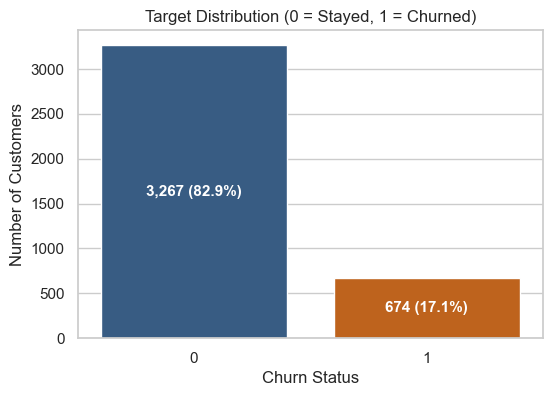

In [28]:
counts = df[TARGET].value_counts()
rate = df[TARGET].mean()
print(f"Target Counts:\n{counts}")
print(f"\nOverall Churn Rate: {rate:.2%}")
print(f"PR-AUC Baseline (Random Guessing): {rate:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = sns.barplot(x=counts.index, y=counts.values, ax=ax, palette=["#2b5c8f", "#d95f02"])
ax.set(title="Target Distribution (0 = Stayed, 1 = Churned)", xlabel="Churn Status", ylabel="Number of Customers")
for p in bars.patches:
    height = p.get_height()
    ax.annotate(f"{int(height):,} ({height/len(df):.1%})",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.show()

## 5. Single-variable analysis

### 5.1 Numeric columns

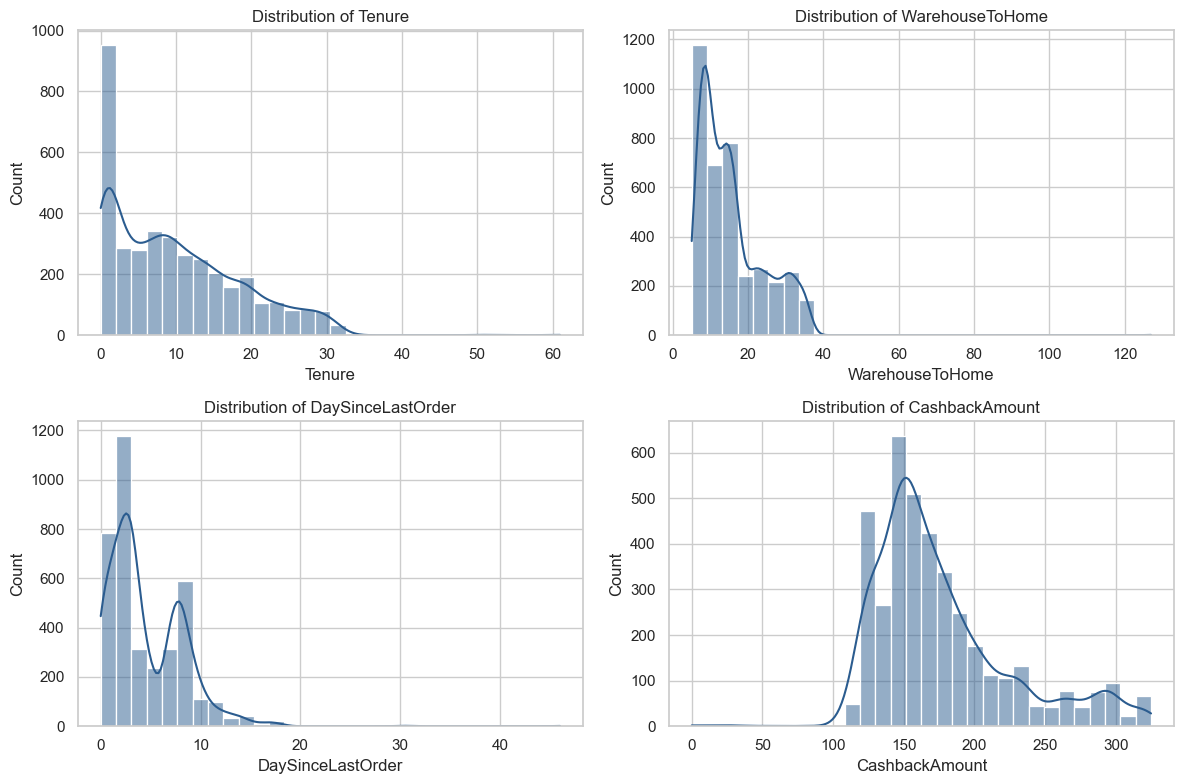

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c].dropna(), bins=30, kde=True, ax=ax, color="#2b5c8f")
    ax.set_title(f"Distribution of {c}")
plt.tight_layout()
plt.show()

### 5.2 Discrete and categorical columns

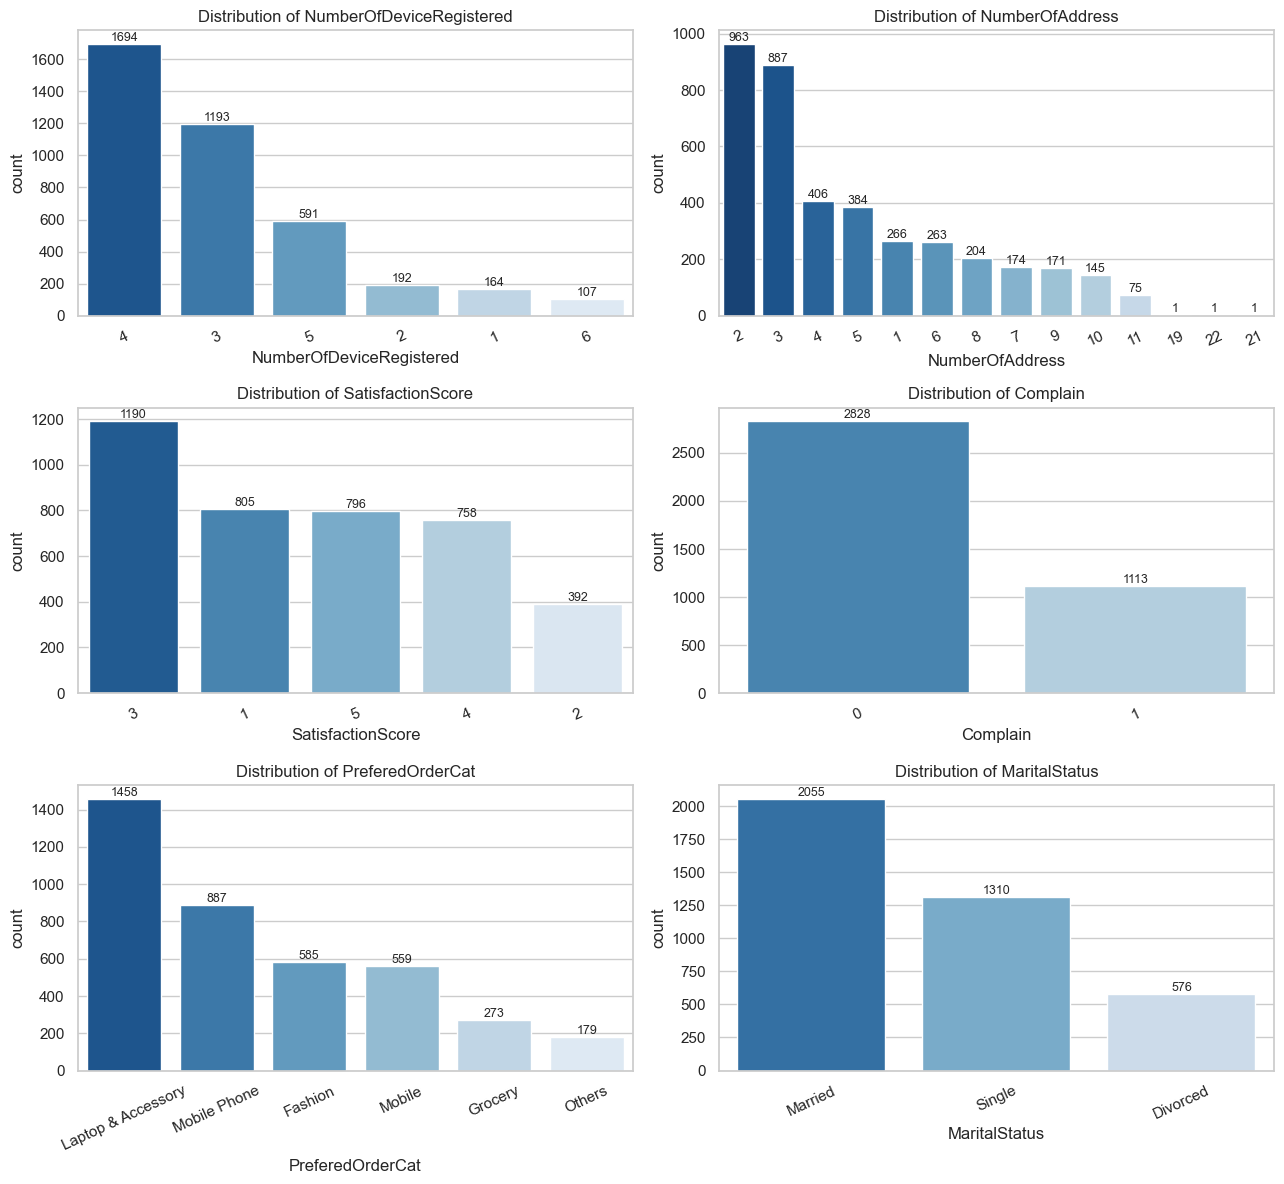

In [30]:
cat_like = discrete_cols + ["PreferedOrderCat", "MaritalStatus"]

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, c in zip(axes.ravel(), cat_like):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax, palette="Blues_r")
    ax.set_title(f"Distribution of {c}")
    ax.tick_params(axis="x", rotation=25)
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f"{int(height)}",
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 6. Each feature vs churn

### 6.1 Numeric feature vs churn

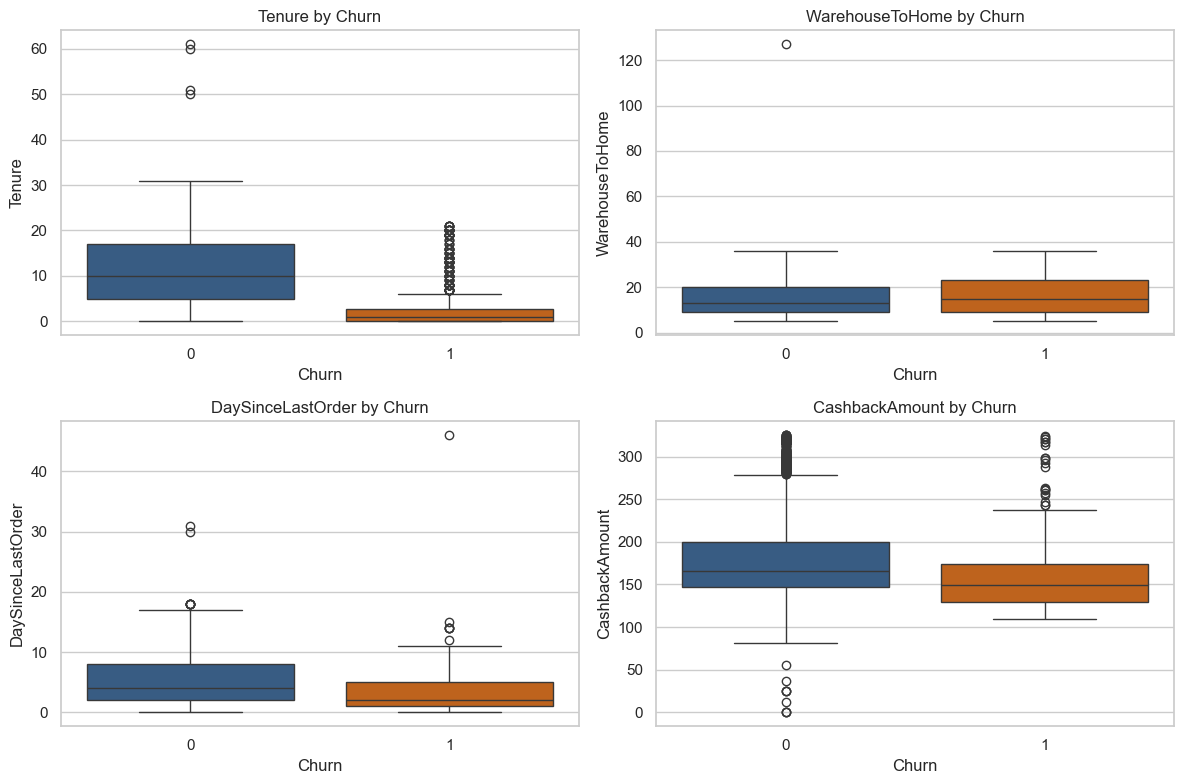

Churn,Stayed (Median),Churned (Median)
Tenure,10.00,1.00
WarehouseToHome,13.00,15.00
DaySinceLastOrder,4.00,2.00
CashbackAmount,166.08,149.34


In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax, palette=["#2b5c8f", "#d95f02"])
    ax.set_title(f"{c} by Churn")
plt.tight_layout()
plt.show()

display(df.groupby(TARGET)[num_cols].median().T.rename(columns={0: "Stayed (Median)", 1: "Churned (Median)"}))

### 6.2 Churn rate by category & sample size validation

In [32]:
def churn_summary(col):
    return (df.groupby(col, dropna=False)[TARGET]
              .agg(customers="count", churn_rate="mean")
              .assign(churn_rate=lambda d: (d.churn_rate * 100).round(1))
              .sort_values("churn_rate", ascending=False))

for c in cat_like:
    print(f"Churn Summary: {c}")
    display(churn_summary(c))

Churn Summary: NumberOfDeviceRegistered


,customers,churn_rate
NumberOfDeviceRegistered,,
6,107,34.60
5,591,22.50
4,1694,17.40
3,1193,14.90
1,164,11.00
2,192,7.30


Churn Summary: NumberOfAddress


,customers,churn_rate
NumberOfAddress,,
19,1,100.00
11,75,26.70
7,174,25.90
8,204,20.10
10,145,19.30
9,171,18.70
2,963,18.50
3,887,18.50
6,263,17.90


Churn Summary: SatisfactionScore


...

,customers,churn_rate
Complain,,
1,1113,32.80
0,2828,10.90


Churn Summary: PreferedOrderCat


,customers,churn_rate
PreferedOrderCat,,
Mobile Phone,887,28.70
Mobile,559,28.40
Fashion,585,16.10
Laptop & Accessory,1458,9.70
Others,179,6.70
Grocery,273,4.40


Churn Summary: MaritalStatus


,customers,churn_rate
MaritalStatus,,
Single,1310,27.10
Divorced,576,15.50
Married,2055,11.20


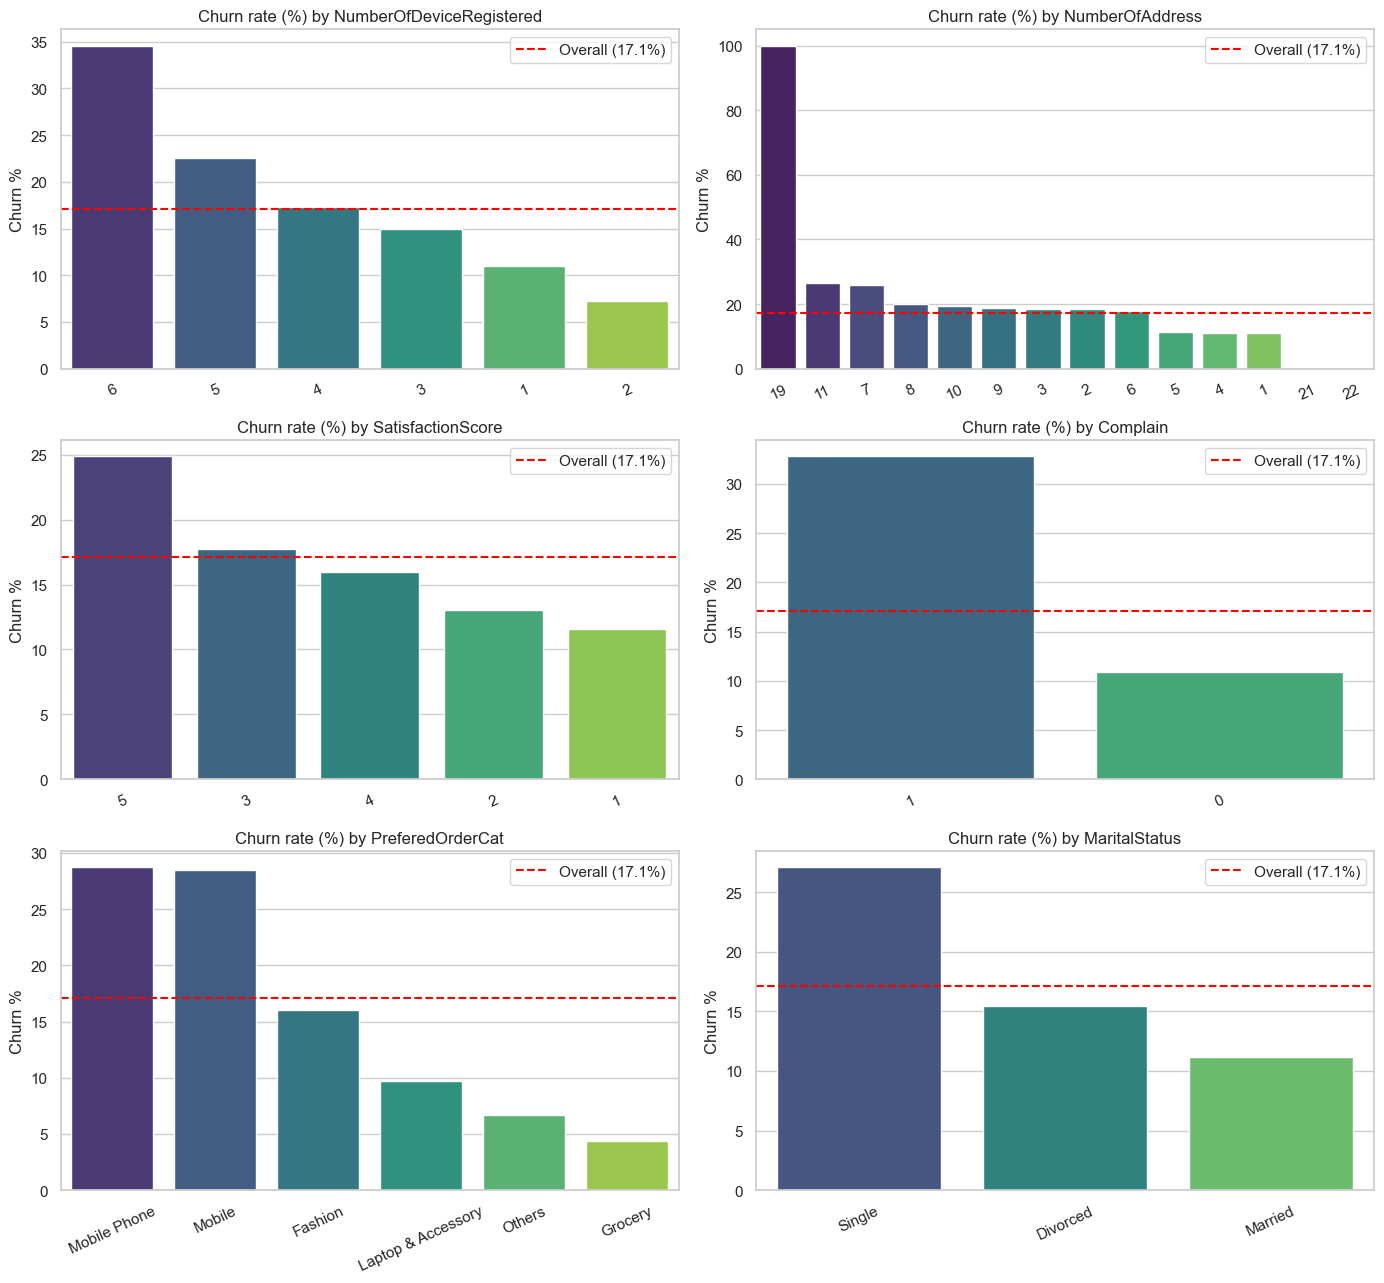

In [33]:
def churn_rate_by(col, ax):
    summary = (df.groupby(col)[TARGET]
                 .agg(count="count", rate="mean")
                 .assign(rate_pct=lambda d: d["rate"] * 100)
                 .sort_values("rate_pct", ascending=False))
    
    bars = sns.barplot(x=summary.index.astype(str), y=summary["rate_pct"], ax=ax, palette="viridis")
    ax.axhline(df[TARGET].mean() * 100, color="red", ls="--", lw=1.5, label=f"Overall ({df[TARGET].mean()*100:.1f}%)")
    ax.set(title=f"Churn rate (%) by {col}", xlabel="", ylabel="Churn %")
    ax.tick_params(axis="x", rotation=25)
    ax.legend()

fig, axes = plt.subplots(3, 2, figsize=(14, 13))
for ax, c in zip(axes.ravel(), cat_like):
    churn_rate_by(c, ax)
plt.tight_layout()
plt.show()

### 6.3 Churn rate by tenure band

,customers,churn_rate
Tenure,,
0-3 mo,1089,43.20
4-6 mo,430,7.00
7-12 mo,927,5.30
13-24 mo,1018,6.00
25+ mo,283,0.00


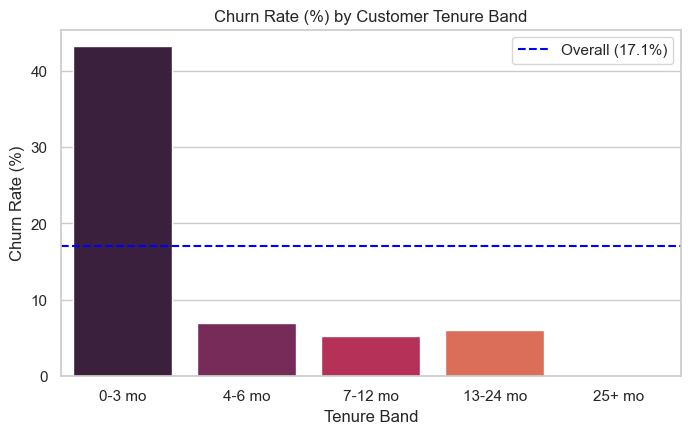

In [34]:
bins = [-1, 3, 6, 12, 24, np.inf]
labels = ["0-3 mo", "4-6 mo", "7-12 mo", "13-24 mo", "25+ mo"]
tenure_band = pd.cut(df["Tenure"], bins=bins, labels=labels)

band = (
    df.groupby(tenure_band, observed=True)[TARGET]
      .agg(customers="count", churn_rate="mean")
      .assign(churn_rate=lambda d: (d["churn_rate"] * 100).round(1))
)
display(band)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = sns.barplot(x=band.index.astype(str), y=band["churn_rate"], ax=ax, palette="rocket")
ax.axhline(df[TARGET].mean() * 100, color="blue", ls="--", lw=1.5, label=f"Overall ({df[TARGET].mean()*100:.1f}%)")
ax.set(title="Churn Rate (%) by Customer Tenure Band", xlabel="Tenure Band", ylabel="Churn Rate (%)")
ax.legend()
plt.show()

## 7. Correlation

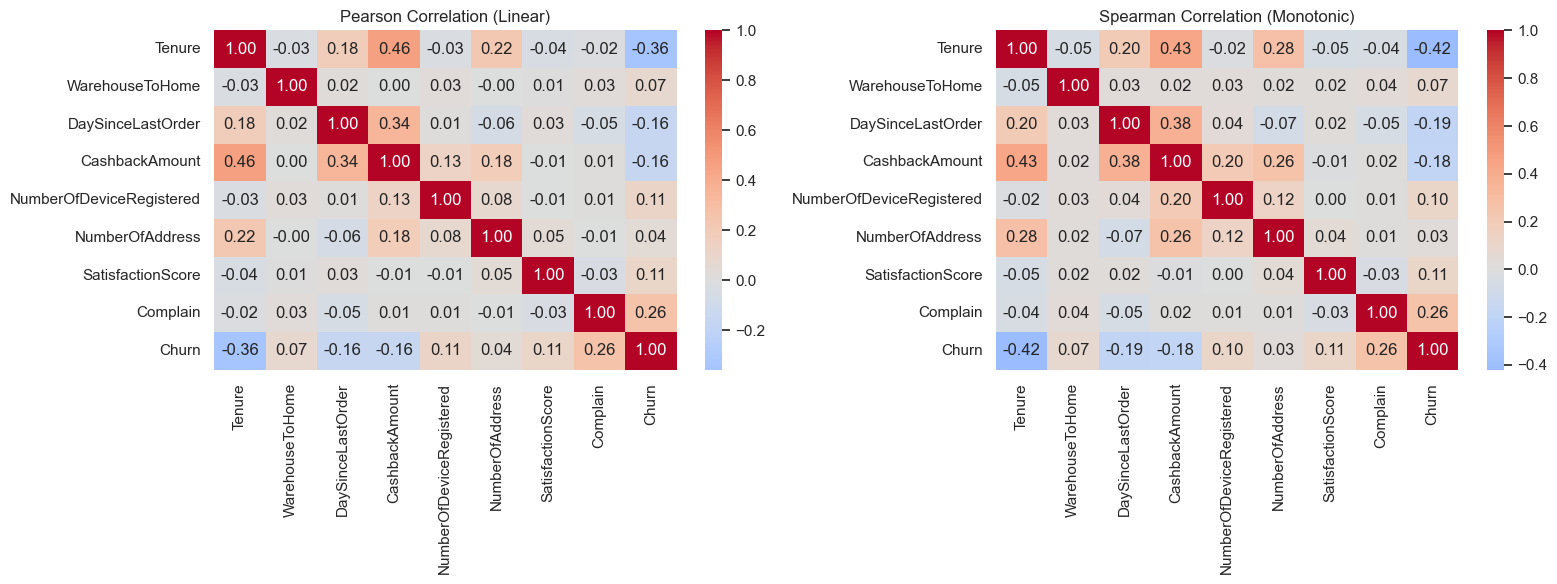

Feature Correlation with Target (Churn)


,Pearson_r,Spearman_rho
Churn,1.00,1.00
Tenure,-0.36,-0.42
Complain,0.26,0.26
DaySinceLastOrder,-0.16,-0.19
CashbackAmount,-0.16,-0.18
SatisfactionScore,0.11,0.11
NumberOfDeviceRegistered,0.11,0.10
WarehouseToHome,0.07,0.07
NumberOfAddress,0.04,0.03


In [35]:
corr_cols = num_cols + ["NumberOfDeviceRegistered", "NumberOfAddress", "SatisfactionScore", "Complain", TARGET]

corr_pearson = df[corr_cols].corr(method="pearson")
corr_spearman = df[corr_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Pearson Correlation (Linear)")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Spearman Correlation (Monotonic)")

plt.tight_layout()
plt.show()

corr_summary = pd.DataFrame({
    "Pearson_r": corr_pearson[TARGET],
    "Spearman_rho": corr_spearman[TARGET]
}).sort_values(by="Spearman_rho", key=abs, ascending=False)

print("Feature Correlation with Target (Churn)")
display(corr_summary)

## 8. Key Insights & Recommendations

### 8.1 Data Quality Decisions

| Issue | Finding | Decision / Pipeline Action |
|---|---|---|
| **Duplicates** | 671 rows (17.0%), 0 contradictory labels | **Drop before train/test split** to prevent data leakage and metric inflation. |
| **Missing Values** | `Tenure` (4.9% missing $\rightarrow$ 33.0% churn vs 16.3% present)<br>`WarehouseToHome` (4.3% missing $\rightarrow$ 35.5% churn vs 16.3% present) | **Add binary missing indicators** (`_isna`) + Train-fitted median imputation. |
| **Categories** | `Mobile` (559 rows) & `Mobile Phone` (887 rows) both churn at ~28.6% | **Merge** `Mobile` $\rightarrow$ `Mobile Phone` into a single category. |
| **Outliers** | `WarehouseToHome` max = 127 km (p99 = 35 km, IQR upper = 39 km) | **Cap at 99th percentile** (fitted on train fold). Retain `Tenure` & `DaySinceLastOrder`. |

### 8.2 Top Business Insights (Quantified)
1. **Complaints $\rightarrow$ Churn ($3\times$ Risk):** Churn rate is **32.8%** with complaints vs. **10.9%**. *Action:* Implement a 24-hour rapid complaint resolution SLA.
2. **The First 90 Days Hazard:** Churn is **43.2%** for tenure 0–3 months, plunging to **7.0%** at 4–6 months and **0.0%** past 25 months. *Action:* Focus onboarding kits, proactive outreach, and loyalty incentives on month 1–3.
3. **Single Customer Vulnerability:** Single customers churn at **27.1%** vs. **11.2%** for Married customers.
4. **Product Category Divergence:** Mobile Phone buyers churn at **28.6%** (transactional purchases) vs. Grocery buyers at **4.4%** and Laptop & Accessory at **9.7%** (recurring loyalty).

### 8.3 Feature Engineering Roadmap
- **`tenure_band`:** Discretize into `['0-3 mo', '4-6 mo', '7-12 mo', '13-24 mo', '25+ mo']` to capture the non-linear cliff.
- **Missing Indicators:** Binary flags `tenure_isna` and `warehouse_to_home_isna`.
- **Category Standardization:** Map `'Mobile'` $\rightarrow$ `'Mobile Phone'`.
- **Risk Interaction Terms:** `Complain * (Tenure <= 3)` and `Complain * Single`.
- **Outlier Capper:** 99th-percentile capping transformer on `WarehouseToHome` fitted strictly on train.

### 8.4 Modeling Strategy & Guardrails
- **Class Imbalance & Metrics:** Churn rate is **17.10%** (PR-AUC baseline = **0.171**). Optimize for **PR-AUC** and **Expected Business Cost** ($500 False Negative vs. $50 False Positive).
- **Leakage Prevention:** Ensure `DaySinceLastOrder` and `Complain` represent pre-churn status recorded before prediction cutoff.
- **Strict Pipeline Isolation:** Fit all imputers, cappers, and scalers strictly on `train` inside `pipeline.fit()`.